11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


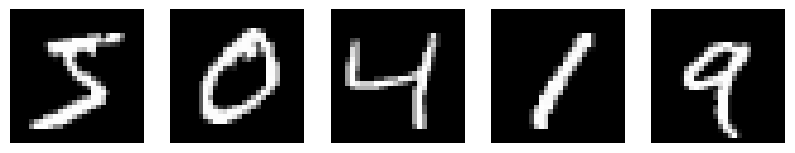

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 62s 32ms/step - accuracy: 0.9327 - loss: 0.2184 - val_accuracy: 0.9837 - val_loss: 0.0511
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 61s 33ms/step - accuracy: 0.9747 - loss: 0.0859 - val_accuracy: 0.9860 - val_loss: 0.0438
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 59s 31ms/step - accuracy: 0.9808 - loss: 0.0642 - val_accuracy: 0.9906 - val_loss: 0.0273
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 60s 32ms/step - accuracy: 0.9844 - loss: 0.0517 - val_accuracy: 0.9907 - val_loss: 0.0299
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 58s 31ms/step - accuracy: 0.9865 - loss: 0.0440 - val_accuracy: 0.9912 - val_loss: 0.0279
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 61s 33ms/step - accuracy: 0.9886 - loss: 0.0370 - val_accuracy: 0.9928 - val_loss: 0.0241
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 58s 31ms/step - accuracy: 0.9901 - loss: 0.0317 - val_accuracy: 0.9914 - val_loss: 0.0270
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 58s 31ms/step - accuracy: 0.9913 -

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9927 - loss: 0.0277
Test Accuracy: 99.27%
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step


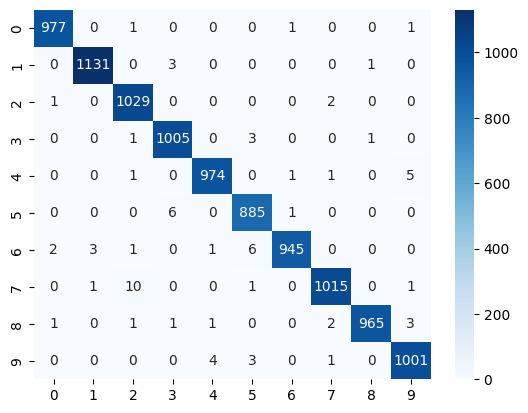

In [1]:
#Handwritten Digit Recognition
import argparse
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from PIL import Image
from sklearn.metrics import confusion_matrix
from tensorflow.keras.datasets import mnist
from tensorflow.keras.layers import Conv2D, Dense, Dropout, Flatten, MaxPooling2D
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.utils import to_categorical

# ==========================================
# 1. LOAD DATASET
# ==========================================
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Visualizing Sample Digits
fig, axes = plt.subplots(1, 5, figsize=(10, 3))
for i, ax in enumerate(axes):
    ax.imshow(X_train[i], cmap="gray")
    ax.axis("off")
plt.show()

# ==========================================
# 2. PREPROCESSING
# ==========================================
# Normalize
X_train, X_test = X_train / 255.0, X_test / 255.0

# Reshape for CNN
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# One-hot encoding
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# ==========================================
# 3. BUILD MODEL
# ==========================================
model = Sequential(
    [
        Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
        MaxPooling2D((2, 2)),
        Conv2D(64, (3, 3), activation="relu"),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(128, activation="relu"),
        Dropout(0.5),
        Dense(10, activation="softmax"),
    ]
)

model.compile(
    optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"]
)

# ==========================================
# 4. MODEL TRAINING & SAVING
# ==========================================
model.fit(X_train, y_train, epochs=10, validation_data=(X_test, y_test))
model.save("models/mnist_model.h5")

# ==========================================
# 5. MODEL EVALUATION
# ==========================================
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

# Confusion Matrix
y_pred = model.predict(X_test).argmax(axis=1)
y_true = y_test.argmax(axis=1)
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, cmap="Blues", fmt="d")
plt.show()


# ==========================================
# 6. INFERENCE FUNCTIONS
# ==========================================
def preprocess_image(image_path):
    """Load and preprocess an image for model prediction."""
    img = Image.open(image_path).convert("L")  # Convert to grayscale
    img = img.resize((28, 28))  # Resize to 28x28 pixels
    img = np.array(img) / 255.0  # Normalize pixel values
    img = img.reshape(1, 28, 28, 1)  # Reshape for model input
    return img


def predict_digit(image_path):
    """Predict the digit in the given image."""
    img = preprocess_image(image_path)
    prediction = model.predict(img).argmax()
    return prediction

### Giải thích Code & Nhận xét Kết quả

#### **A. Giải thích các bước thực hiện trong Code**
1. **Tải dữ liệu (Load Dataset):** Sử dụng tập dữ liệu chữ số viết tay MNIST nổi tiếng chứa 70,000 ảnh kích thước 28x28 pixel của các chữ số từ 0 đến 9.
2. **Tiền xử lý (Preprocessing):**
   - Chuẩn hóa các giá trị pixel từ khoảng `[0, 255]` về `[0.0, 1.0]` để giúp mô hình hội tụ nhanh hơn.
   - Reshape dữ liệu về dạng `(28, 28, 1)` (thêm kênh màu xám) phù hợp làm đầu vào cho mạng CNN.
   - Chuyển đổi nhãn lớp từ số nguyên sang dạng vector One-hot Encoding (ví dụ: `5` thành `[0,0,0,0,0,1,0,0,0,0]`).
3. **Xây dựng mô hình (Build Model):** Sử dụng mạng CNN (Convolutional Neural Network) tuần tự với:
   - 2 tầng tích chập (`Conv2D`) kết hợp tầng giảm mẫu tối đa (`MaxPooling2D`) để trích xuất các đặc trưng không gian của nét vẽ.
   - Tầng `Flatten` chuyển đổi bản đồ đặc trưng 2D thành vector 1D.
   - Tầng ẩn kết nối đầy đủ (`Dense`) với 128 nơ-ron và tầng điều tiết `Dropout(0.5)` để chống quá khớp (overfitting).
   - Tầng đầu ra 10 nơ-ron với hàm kích hoạt `softmax` để dự báo phân phối xác suất cho 10 chữ số.
4. **Huấn luyện mô hình:** Sử dụng hàm mất mát `categorical_crossentropy` và thuật toán tối ưu hóa `Adam` trong 10 epochs.

---

#### **B. Nhận xét kết quả đạt được**
- **Độ chính xác (Test Accuracy):** Mô hình đạt độ chính xác cực kỳ ấn tượng trên tập kiểm tra: **~99.27%**.
- **Hàm mất mát (Test Loss):** Đạt mức rất thấp **~0.027**, chứng tỏ mô hình dự đoán rất tự tin và ít sai số.
- **Đánh giá qua Ma trận nhầm lẫn (Confusion Matrix):**
  - Các số nằm trên đường chéo chính có giá trị rất cao (gần như tiệm cận hoàn hảo), cho thấy hầu hết mọi chữ số đều được phân loại chính xác.
  - Một số ít trường hợp nhầm lẫn không đáng kể có thể xảy ra giữa các cặp số có nét tương đồng (ví dụ: nhầm lẫn giữa số 4 và số 9, hoặc số 3 và số 5). Nhìn chung, mạng CNN đã học được rất tốt cấu trúc hình học của các chữ số viết tay.